# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Для эксперимента выбран открытый датасет Ultralytics Construction-PPE (1000 изображений, 12 классов), лицензия CC BY 4.0. Данные скачиваются автоматически из официального архива Ultralytics. Устройство, на котором выполнялся запуск, будет выведено в переменной `DEVICE_NAME`; его нужно указать после выполнения ноутбука. Для реализации использованы документация Ultralytics и код-заготовка этого ноутбука. Финальные метрики и время обучения появятся после запуска с `FAST_MODE = False`; до этого момента результаты не считаются измеренными.

In [9]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.14.1+cpu, device: cpu


In [10]:
FAST_MODE = True   # True - отладка, False - финальный прогон
BONUS_TASKS = set()     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [11]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [12]:
WEIGHTS = 'yolo26n.pt'
model_coco = YOLO(WEIGHTS)
weights_path = Path(model_coco.ckpt_path)

# Фиксируем параметры исходной модели до predict(), который может слить Conv и BatchNorm.
params = sum(p.numel() for p in model_coco.model.parameters())
weights_bytes = weights_path.read_bytes()

# Прогрев и замер задержки на одном изображении 640x640.
dummy = np.zeros((640, 640, 3), dtype=np.uint8)
for _ in range(3):
    model_coco.predict(dummy, imgsz=640, device=DEVICE, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize()
times = []
for _ in range(12):
    start = time.perf_counter()
    model_coco.predict(dummy, imgsz=640, device=DEVICE, verbose=False)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    times.append((time.perf_counter() - start) * 1000)

MODEL_INFO = {
    'ultralytics': ultralytics.__version__,
    'weights': weights_path.name,
    'sha256': hashlib.sha256(weights_bytes).hexdigest(),
    'size_mb': round(len(weights_bytes) / 1024**2, 2),
    'params': int(params),
    'n_classes_coco': len(model_coco.names),
    'latency_ms': float(np.mean(times)),
}
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.29,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 191.65033708333826}

In [13]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.29,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 191.65033708333826}

**Ответ:** Я выбрал `yolo26n`, потому что это самая компактная версия семейства и она подходит для ограниченного бюджета обучения на T4. У неё меньше параметров и ниже задержка, чем у `yolo26s`, поэтому на нашем датасете можно быстрее проверить полный цикл обучения. Более крупная модель потенциально точнее, но потребует больше видеопамяти и времени. Для учебного эксперимента важен баланс между скоростью и качеством. Код и предобученные веса Ultralytics распространяются по лицензии AGPL-3.0: при распространении производного программного продукта нужно соблюдать условия этой лицензии, в том числе требования по предоставлению исходного кода в предусмотренных ею случаях. Точные параметры, хеш весов и задержка приведены в выводе `MODEL_INFO`.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [14]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])
    n_head = len(layers) - 1
    counts = {'backbone': 0, 'neck': 0, 'head': 0}
    for i, layer in enumerate(layers):
        block = 'backbone' if i < n_backbone else ('head' if i == n_head else 'neck')
        counts[block] += sum(p.numel() for p in layer.parameters())
    return counts


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели)
    detect = det_model.model[-1]
    captured = []

    def hook(module, inputs, output):
        features = inputs[0]
        captured.extend([tuple(x.shape) for x in features])

    handle = detect.register_forward_hook(hook)
    was_training = det_model.training
    device = next(det_model.parameters()).device
    try:
        det_model.eval()
        dummy = torch.zeros(1, 3, imgsz, imgsz, device=device)
        with torch.inference_mode():
            output = det_model(dummy)
    finally:
        handle.remove()
        det_model.train(was_training)
    return captured, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [15]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [16]:
print('Выход модели:', shapes(out))
print('Доли параметров:', {k: f'{v / total:.1%}' for k, v in blocks.items()})

Выход модели: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]
Доли параметров: {'backbone': '53.1%', 'neck': '34.9%', 'head': '12.0%'}


**Ответ:** Backbone извлекает признаки из изображения: на ранних слоях находятся простые границы и текстуры, на более глубоких — признаки объектов. Neck объединяет признаки разных масштабов: за счёт этого голова получает информацию и о крупных объектах, и о небольших деталях. Head делает предсказания классов и координат боксов на нескольких feature maps с разными stride. Детектор anchor-free, потому что ему не нужно заранее задавать набор anchor boxes: координаты объектов предсказываются относительно точек на картах признаков. Число 8400 для входа 640 получается как сумма размеров трёх карт при stride 8, 16 и 32: 80×80 + 40×40 + 20×20. В YOLO26 используются ветки one-to-many и one-to-one: первая помогает обучению, вторая предназначена для финальных предсказаний. Благодаря one-to-one ветке модель может выдавать итоговые боксы без обычного NMS. Фактическое распределение параметров по backbone, neck и head показано выше в выводе ячейки.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [17]:
# Датасет Ultralytics Construction-PPE: 1000 изображений, 12 классов, CC BY 4.0.
# Архив и yaml скачиваются средствами ultralytics.
from ultralytics.data.utils import check_det_dataset

DATASET_YAML_INFO = check_det_dataset('construction-ppe.yaml')
dataset_root = Path(DATASET_YAML_INFO['path'])
class_names = DATASET_YAML_INFO['names']
if isinstance(class_names, dict):
    CLASSES = [class_names[i] for i in sorted(class_names)]
else:
    CLASSES = list(class_names)

DATASET_NAME = ('Ultralytics Construction-PPE, 1000 изображений, 12 классов; '
                'https://docs.ultralytics.com/datasets/detect/construction-ppe/; CC BY 4.0')

def read_yolo_split(split_name):
    image_dir_value = DATASET_YAML_INFO[split_name]
    image_dir = Path(image_dir_value)
    if not image_dir.is_absolute():
        image_dir = dataset_root / image_dir
    image_paths = sorted(p for p in image_dir.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'})
    result, clipped_count, invalid_count = [], 0, 0
    for image_path in image_paths:
        with Image.open(image_path) as im:
            width, height = im.size
        label_path = Path(str(image_path).replace('/images/', '/labels/')).with_suffix('.txt')
        boxes, labels = [], []
        if label_path.exists():
            for line in label_path.read_text(encoding='utf-8').splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue
                cls, cx, cy, bw, bh = map(float, parts)
                x1, y1 = (cx - bw / 2) * width, (cy - bh / 2) * height
                x2, y2 = (cx + bw / 2) * width, (cy + bh / 2) * height
                old = np.array([x1, y1, x2, y2], dtype=float)
                box = np.array([np.clip(x1, 0, width), np.clip(y1, 0, height),
                                np.clip(x2, 0, width), np.clip(y2, 0, height)], dtype=float)
                if not np.allclose(old, box):
                    clipped_count += 1
                if box[2] <= box[0] or box[3] <= box[1]:
                    invalid_count += 1
                    continue
                boxes.append(box)
                labels.append(int(cls))
        result.append(dict(image=str(image_path), width=width, height=height,
                           boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                           labels=np.asarray(labels, dtype=np.int64)))
    return result, clipped_count, invalid_count

records = {}
DATA_CLEANING = {}
for split_name in ('train', 'val', 'test'):
    if DATASET_YAML_INFO.get(split_name):
        records[split_name], n_clipped, n_invalid = read_yolo_split(split_name)
        DATA_CLEANING[split_name] = {'clipped': n_clipped, 'invalid_removed': n_invalid}

print('Датасет:', DATASET_NAME)
print('Классы:', CLASSES)
print('Изображения:', {k: len(v) for k, v in records.items()})
print('Исправление разметки:', DATA_CLEANING)


WARNING ⚠️ Dataset 'construction-ppe.yaml' images not found, missing path '/content/datasets/construction-ppe/images/val'
Unzipping /content/datasets/construction-ppe.zip to /content/datasets/construction-ppe...: 100% ━━━━━━━━━━━━ 2004/2004 325.5files/s 6.2s
Dataset download success ✅ (14.8s), saved to /content/datasets

Датасет: Ultralytics Construction-PPE, 1000 изображений, 12 классов; https://docs.ultralytics.com/datasets/detect/construction-ppe/; CC BY 4.0
Классы: ['helmet', 'gloves', 'vest', 'boots', 'goggles', 'Person', 'no_helmet', 'no_goggle', 'no_gloves', 'no_boots', 'forklift', 'no_vest']
Изображения: {'train': 800, 'val': 200}
Исправление разметки: {'train': {'clipped': 26, 'invalid_removed': 0}, 'val': {'clipped': 3, 'invalid_removed': 0}}


In [18]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 800, 'val': 200}

train: изображений=800, объектов=11902, объектов на изображение в среднем=14.88
{'helmet': 1282, 'gloves': 1548, 'vest': 1476, 'boots': 2003, 'goggles': 612, 'Person': 1962, 'no_helmet': 634, 'no_goggle': 265, 'no_gloves': 839, 'no_boots': 569, 'forklift': 275, 'no_vest': 437}
val: изображений=200, объектов=2961, объектов на изображение в среднем=14.80
{'helmet': 294, 'gloves': 381, 'vest': 340, 'boots': 481, 'goggles': 139, 'Person': 481, 'no_helmet': 179, 'no_goggle': 82, 'no_gloves': 203, 'no_boots': 178, 'forklift': 73, 'no_vest': 130}


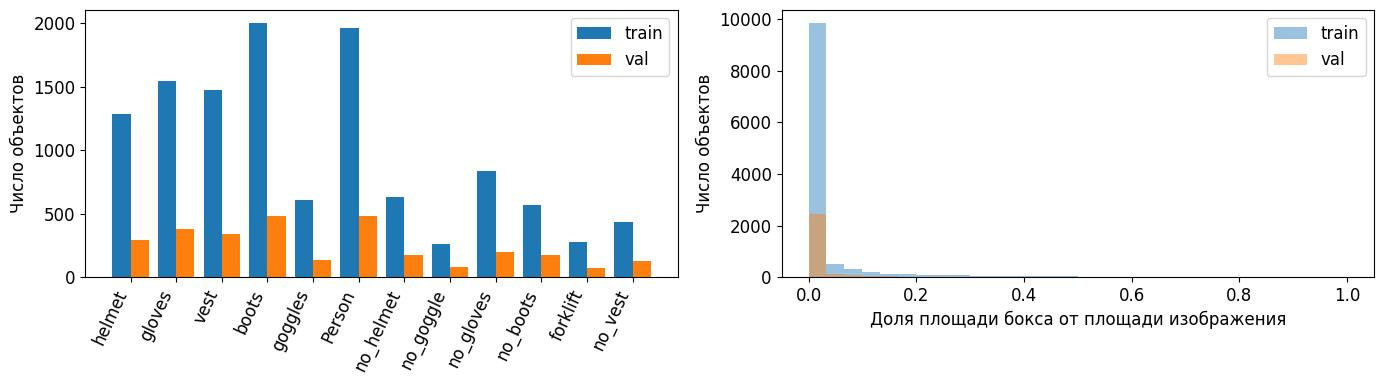

In [19]:
# Статистика по сплитам и классам.
rows = []
for split, recs in records.items():
    counts = np.zeros(len(CLASSES), dtype=int)
    object_sizes = []
    objects_per_image = []
    for rec in recs:
        counts += np.bincount(rec['labels'], minlength=len(CLASSES))
        objects_per_image.append(len(rec['labels']))
        if len(rec['boxes']):
            wh = rec['boxes'][:, 2:4] - rec['boxes'][:, :2]
            object_sizes.extend((wh[:, 0] * wh[:, 1] / (rec['width'] * rec['height'])).tolist())
    rows.append((split, len(recs), int(counts.sum()), float(np.mean(objects_per_image)),
                 counts, np.asarray(object_sizes)))
    print(f'{split}: изображений={len(recs)}, объектов={counts.sum()}, '
          f'объектов на изображение в среднем={np.mean(objects_per_image):.2f}')
    print(dict(zip(CLASSES, counts.tolist())))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(CLASSES))
width = 0.8 / len(rows)
for j, (split, n_images, n_objects, avg, counts, sizes) in enumerate(rows):
    axes[0].bar(x - 0.4 + width/2 + j*width, counts, width, label=split)
axes[0].set_xticks(x, CLASSES, rotation=65, ha='right')
axes[0].set_ylabel('Число объектов')
axes[0].legend()
for split, _, _, _, _, sizes in rows:
    if len(sizes):
        axes[1].hist(sizes, bins=30, alpha=0.45, label=split)
axes[1].set_xlabel('Доля площади бокса от площади изображения')
axes[1].set_ylabel('Число объектов')
axes[1].legend()
plt.tight_layout()
plt.show()

**Ответ:** Использован датасет Construction-PPE от Ultralytics. В нём представлены 12 классов, связанных со средствами индивидуальной защиты и строительной площадкой; лицензия — CC BY 4.0. Архив содержит около 1000 изображений и уже разделён на train и val. Точное количество изображений и объектов по каждому классу выводится в статистике выше. По диаграмме можно оценить дисбаланс: классы с заметно меньшими столбцами представлены хуже, поэтому их метрики нужно будет интерпретировать осторожно. Гистограмма долей площади показывает, насколько много в наборе небольших объектов. После проверки разметки число обрезанных и удалённых некорректных боксов также выводится отдельно.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [20]:
def to_yolo(boxes, labels, width, height):
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    if len(boxes) != len(labels):
        raise ValueError('Количество боксов и меток должно совпадать')
    if width <= 0 or height <= 0:
        raise ValueError('Размеры изображения должны быть положительными')
    lines = []
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        cx = ((x1 + x2) / 2) / width
        cy = ((y1 + y2) / 2) / height
        bw = (x2 - x1) / width
        bh = (y2 - y1) / height
        lines.append(f'{int(label)} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}')
    return '\n'.join(lines)


def from_yolo(text, width, height):
    if width <= 0 or height <= 0:
        raise ValueError('Размеры изображения должны быть положительными')
    rows = []
    for line in text.splitlines():
        if line.strip():
            values = line.split()
            if len(values) != 5:
                raise ValueError(f'Некорректная строка YOLO: {line}')
            rows.append([float(v) for v in values])
    if not rows:
        return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.int64)
    arr = np.asarray(rows, dtype=float)
    labels = arr[:, 0].astype(np.int64)
    cx, cy, bw, bh = arr[:, 1:].T
    boxes = np.column_stack([(cx-bw/2)*width, (cy-bh/2)*height,
                             (cx+bw/2)*width, (cy+bh/2)*height])
    return boxes.astype(np.float32), labels

In [21]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [26]:
YOLO_ROOT = DATA_ROOT / 'yolo'

def export_split(recs, split):
    image_out = YOLO_ROOT / 'images' / split
    label_out = YOLO_ROOT / 'labels' / split
    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)
    for index, rec in enumerate(recs):
        src = Path(rec['image'])
        stem = f'{index:06d}_{src.stem}'
        dst = image_out / f'{stem}{src.suffix.lower()}'
        shutil.copy2(src, dst)
        txt = to_yolo(rec['boxes'], rec['labels'], rec['width'], rec['height'])
        (label_out / f'{stem}.txt').write_text(txt, encoding='utf-8')

order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'
print(DATA_YAML.read_text())

path: /content/data/yolo
train: images/train
val: images/val
names:
  0: helmet
  1: gloves
  2: vest
  3: boots
  4: goggles
  5: Person
  6: no_helmet
  7: no_goggle
  8: no_gloves
  9: no_boots
  10: forklift
  11: no_vest



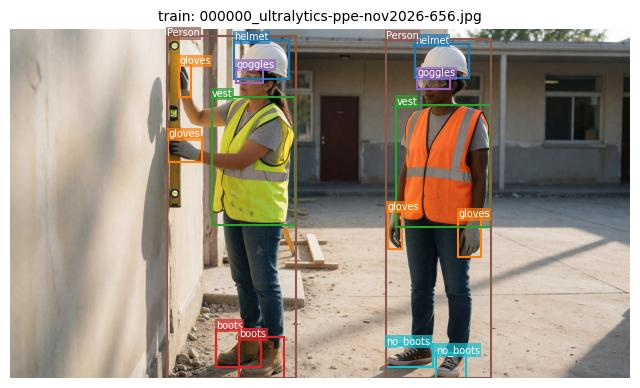

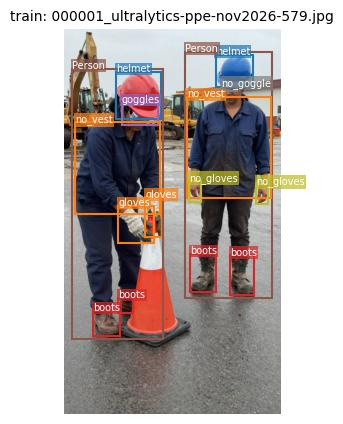

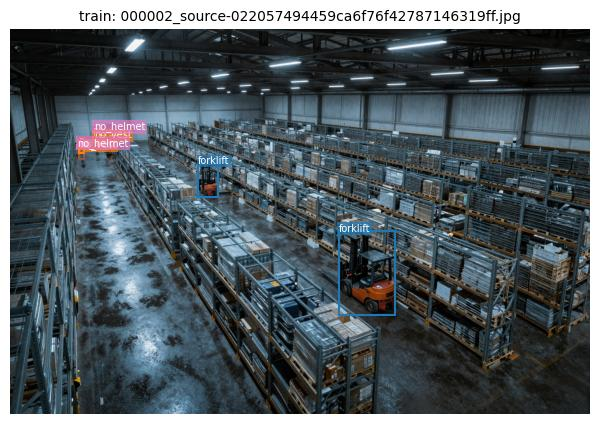

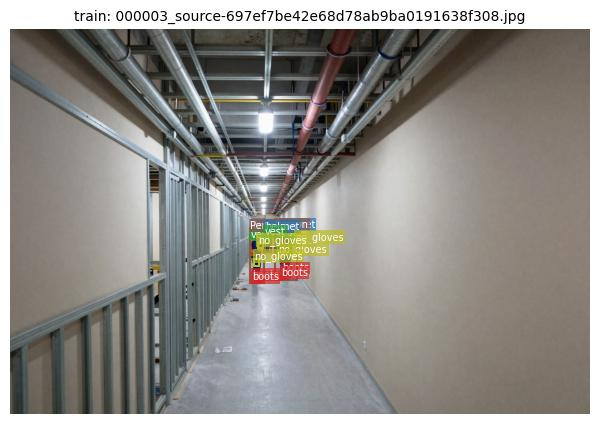

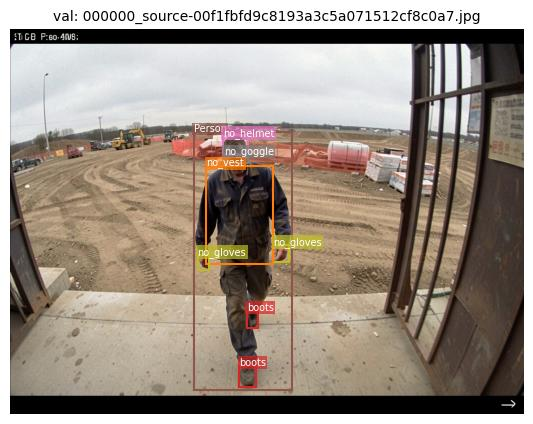

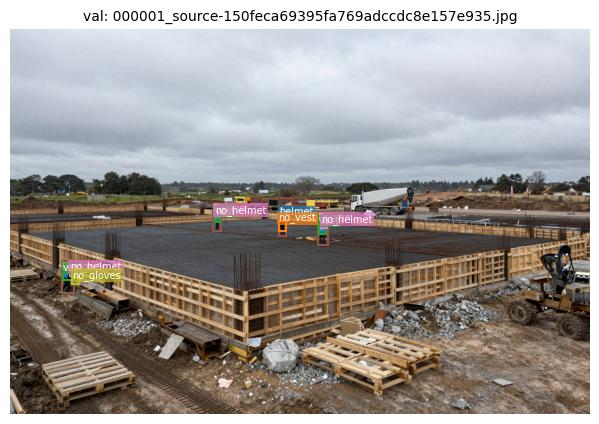

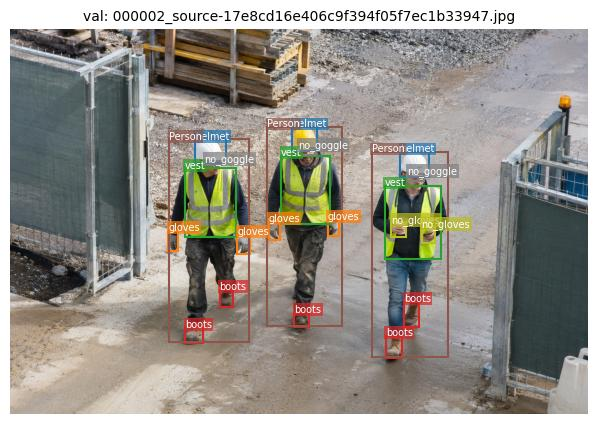

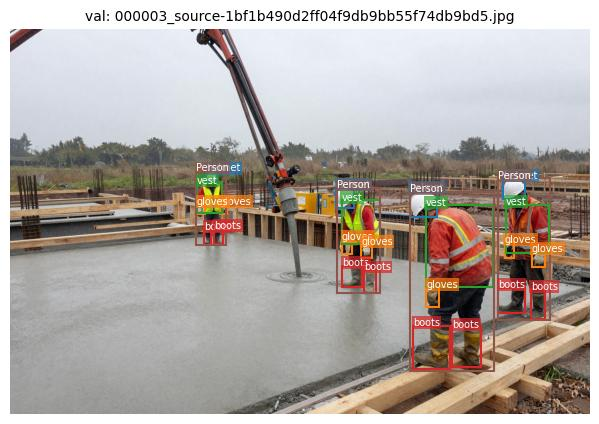

Обратное чтение экспортированной разметки выполнено.


In [27]:
for split in ['train', 'val', 'test']:
    if split not in records:
        continue
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    exported_images = sorted(p for p in image_dir.iterdir() if p.is_file())
    for image_path in exported_images[:min(4, len(exported_images))]:
        with Image.open(image_path) as im:
            image = np.asarray(im.convert('RGB'))
            width, height = im.size
        label_path = label_dir / f'{image_path.stem}.txt'
        boxes, labels = from_yolo(label_path.read_text(encoding='utf-8'), width, height)
        fig, ax = plt.subplots(figsize=(8, 5))
        draw_boxes(ax, image, boxes, labels, CLASSES, title=f'{split}: {image_path.name}')
        plt.show()
print('Обратное чтение экспортированной разметки выполнено.')

**Ответ:** Тест туда-обратно проверяет, что после перевода координат из пикселей в нормированные значения и обратно боксы и метки сохраняются с допустимой погрешностью. Он не проверяет, правильно ли исходная рамка охватывает объект, соответствует ли метка самому объекту и не перепутан ли порядок классов. На изображении проще всего заметить перепутанные оси X и Y, неверный масштаб нормализации, смещение рамок и ситуацию, когда рамка обрезает часть объекта или захватывает лишний фон.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [28]:
# Сопоставляем классы датасета с COCO. Из классов Construction-PPE совпадает только Person.
coco_name_to_id = {str(v).lower(): int(k) for k, v in model_coco.names.items()}
dataset_to_coco = {}
for i, name in enumerate(CLASSES):
    normalized = str(name).lower().replace('_', '').replace(' ', '')
    if normalized == 'person' and 'person' in coco_name_to_id:
        dataset_to_coco[i] = coco_name_to_id['person']

coco_preds = []
for rec in records[FINAL_SPLIT]:
    result = model_coco.predict(rec['image'], conf=0.001, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    coco_labels = result.boxes.cls.cpu().numpy().astype(int)
    keep_boxes, keep_scores, keep_labels = [], [], []
    for box, score, label in zip(boxes, scores, coco_labels):
        matching = [dst for dst, src in dataset_to_coco.items() if src == label]
        if matching:
            keep_boxes.append(box)
            keep_scores.append(score)
            keep_labels.append(matching[0])
    coco_preds.append(dict(boxes=np.asarray(keep_boxes, dtype=float).reshape(-1, 4),
                           scores=np.asarray(keep_scores, dtype=float),
                           labels=np.asarray(keep_labels, dtype=np.int64)))

coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
print('Совпадающие классы:', {CLASSES[k]: model_coco.names[v] for k, v in dataset_to_coco.items()})
print('COCO mAP50:', coco_map50)

Совпадающие классы: {'Person': 'person'}
COCO mAP50: 0.06536945583486185


In [29]:
def heuristic_detect(image_path):
    # Тривиальный бейзлайн: один средний по train бокс для каждого класса.
    image = Image.open(image_path)
    width, height = image.size
    boxes, scores, labels = [], [], []
    for class_id, mean_box in enumerate(MEAN_BOXES):
        if mean_box is None:
            continue
        x1, y1, x2, y2 = mean_box
        boxes.append([x1 * width, y1 * height, x2 * width, y2 * height])
        scores.append(0.05)
        labels.append(class_id)
    return dict(boxes=np.asarray(boxes, dtype=float).reshape(-1, 4),
                scores=np.asarray(scores, dtype=float),
                labels=np.asarray(labels, dtype=np.int64))

In [30]:
# Средние нормированные координаты бокса каждого класса считаются только по train.
MEAN_BOXES = []
for class_id in range(len(CLASSES)):
    normalized_boxes = []
    for rec in records['train']:
        mask = rec['labels'] == class_id
        if mask.any():
            b = rec['boxes'][mask].astype(float)
            b[:, [0, 2]] /= rec['width']
            b[:, [1, 3]] /= rec['height']
            normalized_boxes.extend(b.tolist())
    MEAN_BOXES.append(np.mean(normalized_boxes, axis=0).tolist() if normalized_boxes else None)

In [31]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'val',
 'coco_map50': 0.06536945583486185,
 'heuristic_map50': 0.0005503417051462076,
 'heuristic_ap50_per_class': {'helmet': 0.00024295432458697764,
  'gloves': 0.0,
  'vest': 2.7746947835738067e-05,
  'boots': 0.0,
  'goggles': 3.786444528587656e-05,
  'Person': 0.005365724512729958,
  'no_helmet': 0.0,
  'no_goggle': 0.0,
  'no_gloves': 0.0,
  'no_boots': 4.928050463236743e-05,
  'forklift': 0.0,
  'no_vest': 0.0008805297266835728}}

**Ответ:** COCO-модель обучалась на другом наборе классов, поэтому большинство категорий средств защиты в Construction-PPE ей незнакомы. Совпадает только класс `Person`, и даже для него качество зависит от ракурса, размера человека и условий съёмки. Эвристика использует среднее положение и размер бокса класса на обучающей выборке. Она не анализирует содержимое изображения, поэтому может случайно попадать в объекты, расположенные примерно в одном и том же месте, но плохо работает при изменении композиции и масштаба. Сравнить конкретные значения mAP50 можно в выводе `BASELINE` после запуска.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [32]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [33]:
TRAIN_ARGS = dict(
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    optimizer='auto',
    lr0=0.01,
    patience=15 if not FAST_MODE else 2,
    close_mosaic=10 if not FAST_MODE else 0,
    degrees=5.0,
    fliplr=0.5,
    flipud=0.0,
    mosaic=1.0,
    plots=True,
    save=True,
    val=True,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

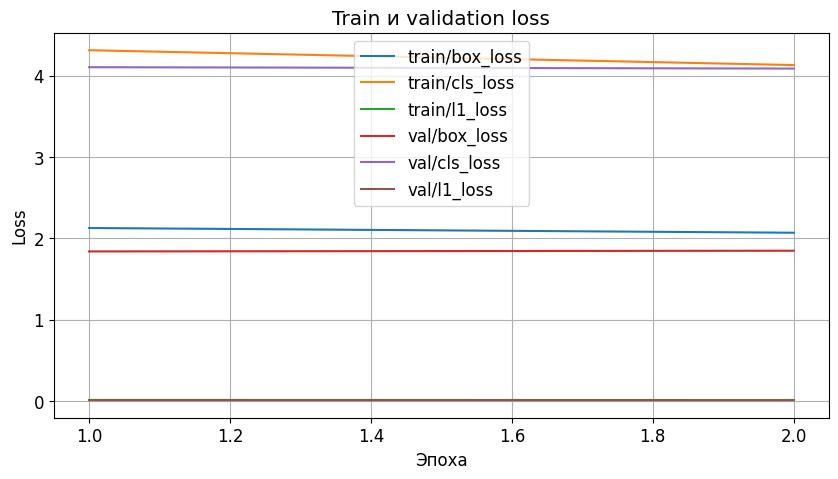

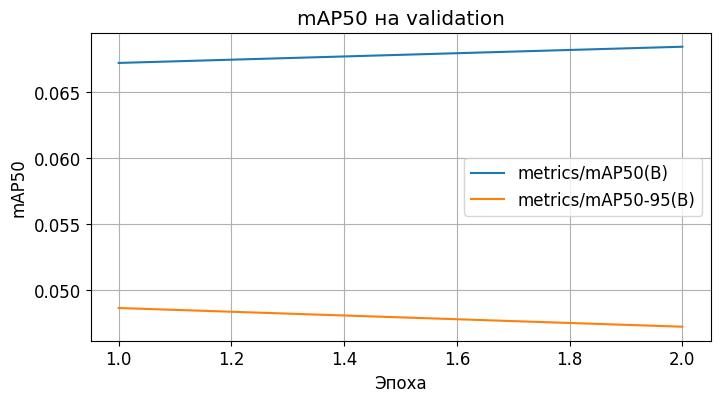

In [34]:
# Кривые train/val loss и mAP50 по эпохам.
history = read_results(run_dir)
loss_keys = [k for k in history if 'loss' in k.lower()]
fig, ax = plt.subplots(figsize=(10, 5))
for key in loss_keys:
    ax.plot(np.arange(1, len(history[key]) + 1), history[key], label=key)
ax.set_xlabel('Эпоха')
ax.set_ylabel('Loss')
ax.set_title('Train и validation loss')
ax.legend()
ax.grid(True)
plt.show()

map_keys = [k for k in history if 'mAP50' in k]
fig, ax = plt.subplots(figsize=(8, 4))
for key in map_keys:
    ax.plot(np.arange(1, len(history[key]) + 1), history[key], label=key)
ax.set_xlabel('Эпоха')
ax.set_ylabel('mAP50')
ax.set_title('mAP50 на validation')
ax.legend()
ax.grid(True)
plt.show()

**Ответ:** Для основного запуска используется `imgsz=640`, чтобы не терять слишком много деталей на небольших объектах. Размер batch выбран с учётом памяти T4, а оптимизатор `auto` позволяет Ultralytics подобрать стандартную конфигурацию для этой модели. Вертикальное отражение отключено, поскольку перевёрнутые строительные сцены нехарактерны для исходных изображений; горизонтальное отражение оставлено как реалистичная аугментация. По графикам после запуска нужно сравнить динамику train и val loss: если train loss продолжает снижаться, а val loss растёт, это признак переобучения. Достаточность числа эпох оценивается по стабилизации val loss и mAP50, а не только по последней эпохе.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [35]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3059.9±239.9 MB/s, size: 543.2 KB)
val: Scanning /content/data/yolo/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 49.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.8it/s 13.7s
                   all        200       2961      0.661     0.0585     0.0673     0.0487
Speed: 0.4ms preprocess, 39.7ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/runs_hw2/val_val
FINAL: {'map50': 0.06733098621560925, 'map50_95': 0.048699925823666605, 'precision': 0.6609180836516071, 'recall': 0.05845613585500308, 'per_class': {'helmet': {'precision': 1.0, 'recall': 0.0, 'map50_95': None, 'map50': None}, 'gloves': {'precision': 0.0, 'recall': 0.0, 

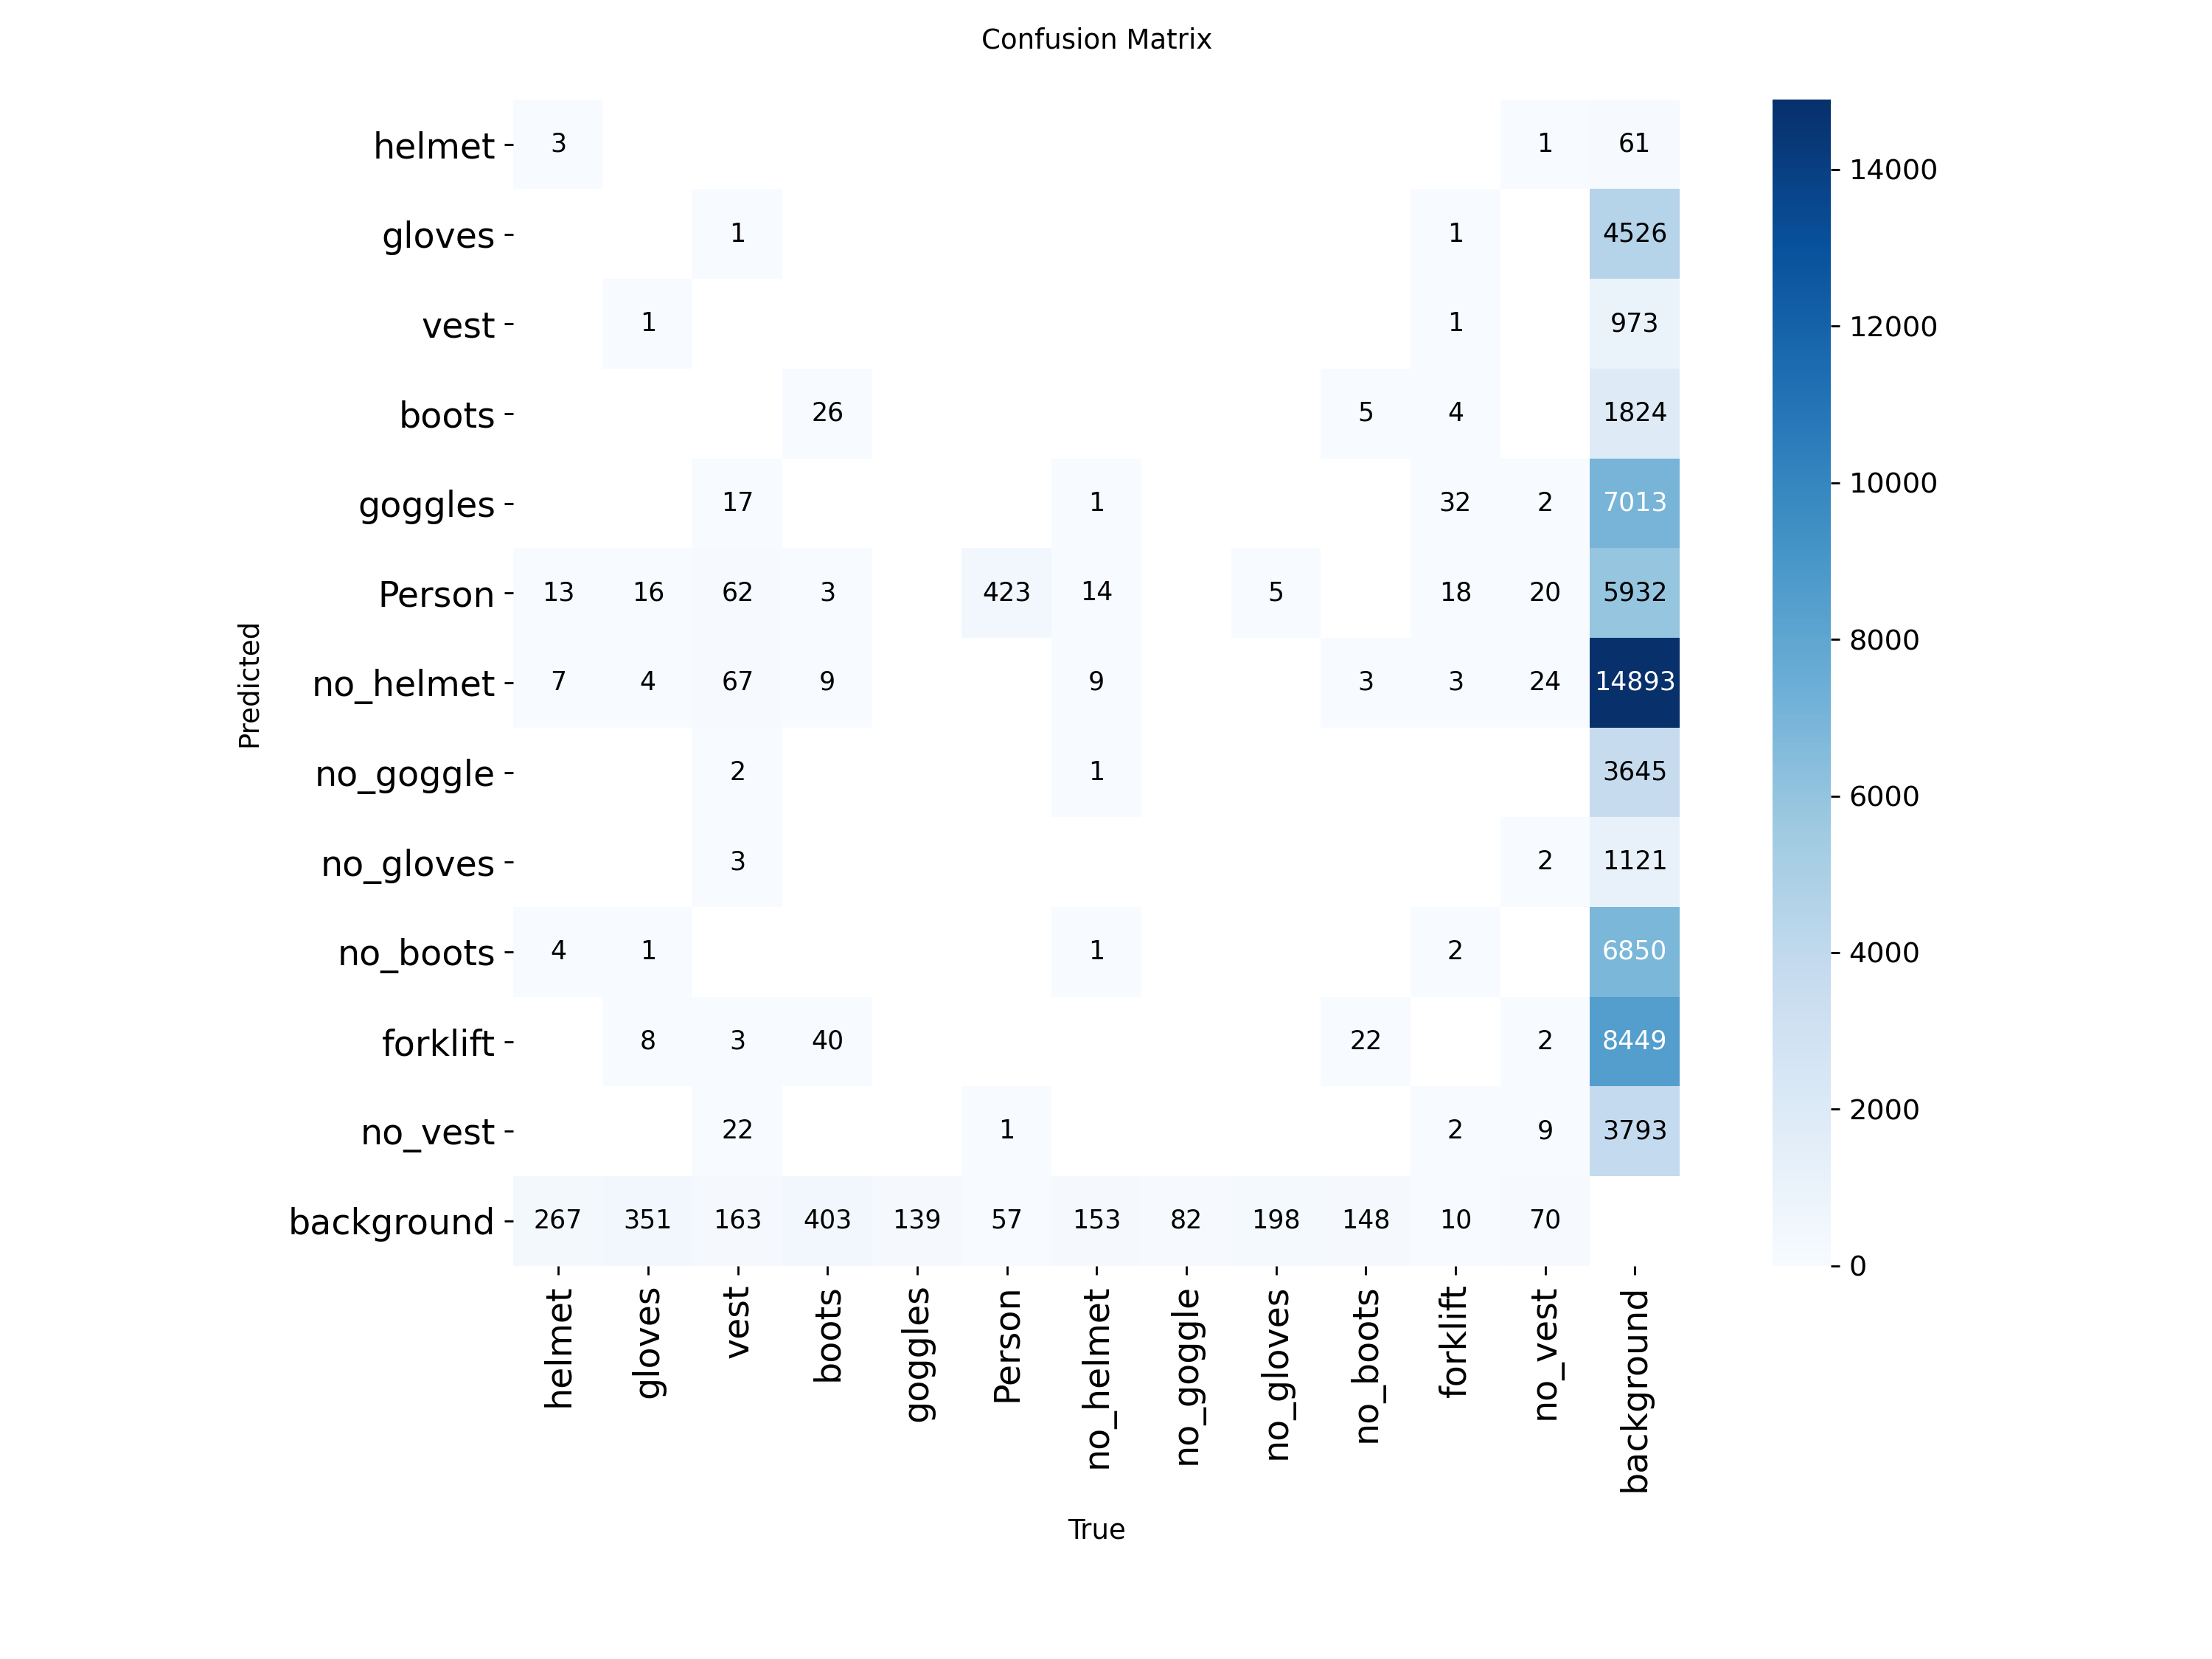

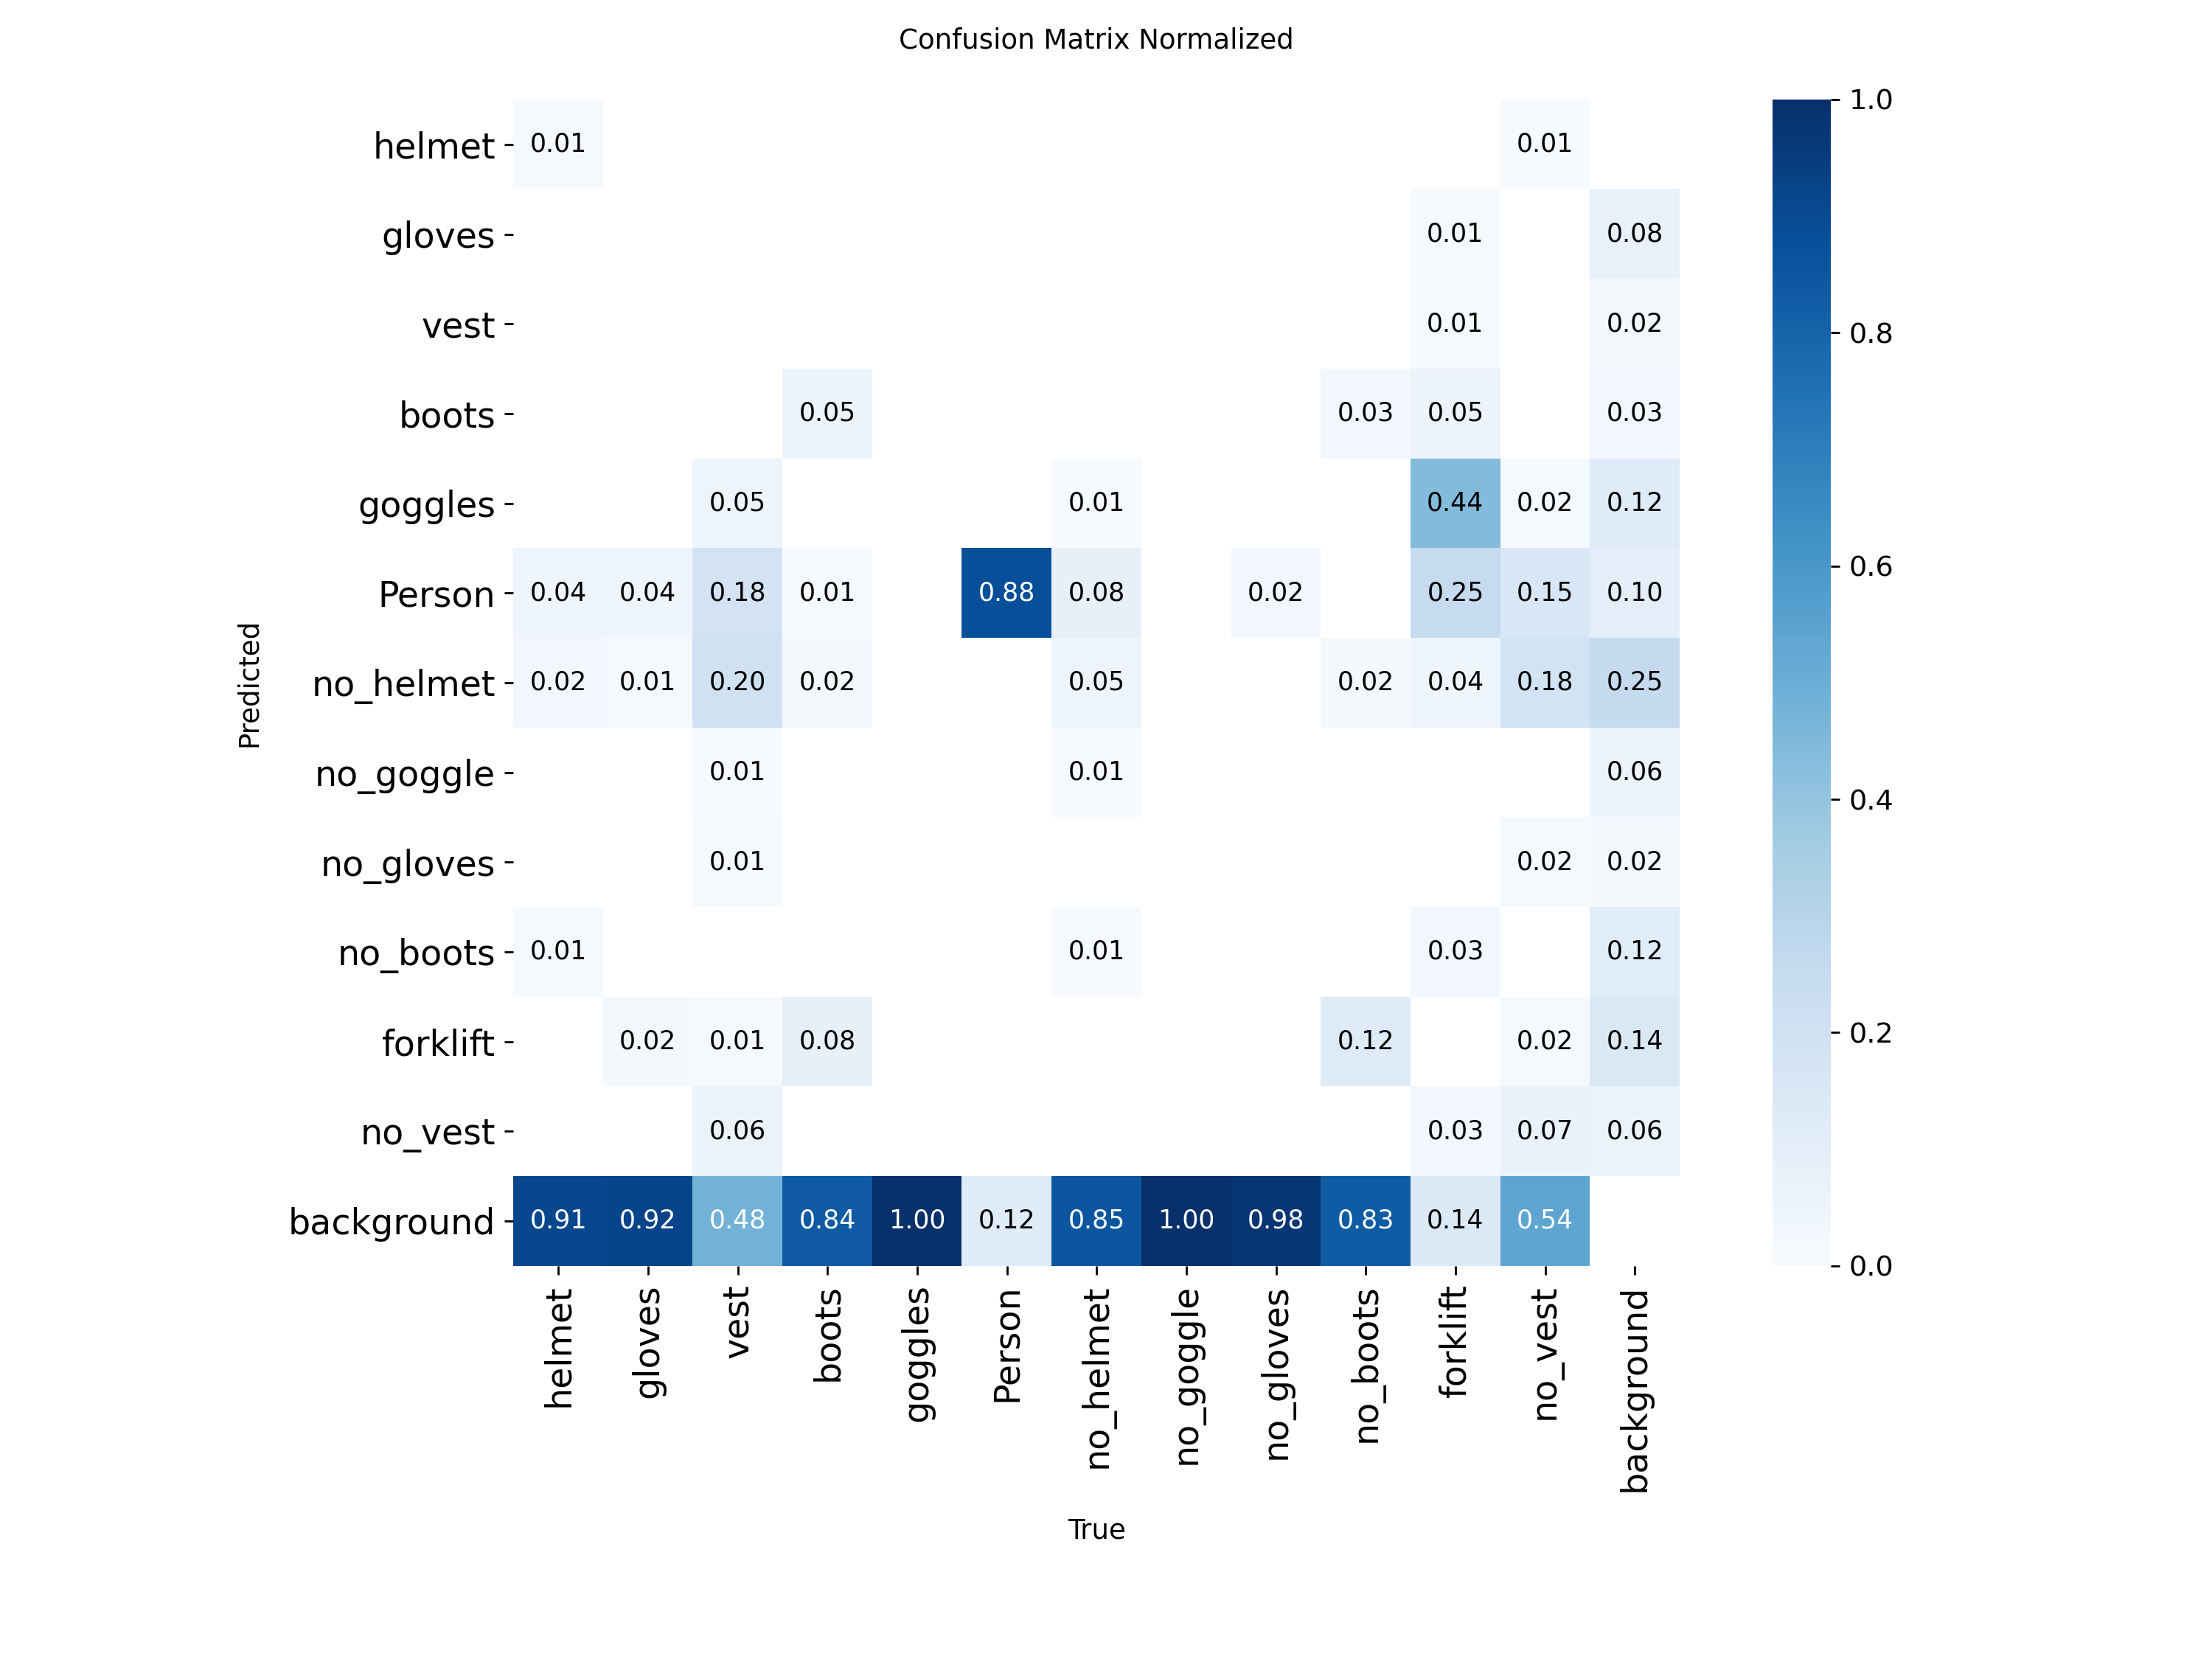

In [36]:
# Валидация лучшего чекпойнта на val и, если присутствует, test.
VAL_RESULTS = {}
for split_name in ('val', 'test'):
    if split_name in records:
        VAL_RESULTS[split_name] = val_metrics(best, split_name, f'val_{split_name}')

metric_result = VAL_RESULTS[FINAL_SPLIT]
box_metrics = metric_result.box
per_class = {}
class_indices = list(getattr(box_metrics, 'ap_class_index', range(len(CLASSES))))
p_values = np.asarray(getattr(box_metrics, 'p', []))
r_values = np.asarray(getattr(box_metrics, 'r', []))
ap_values = np.asarray(getattr(box_metrics, 'ap', []))
for pos, class_id in enumerate(class_indices):
    class_id = int(class_id)
    per_class[CLASSES[class_id]] = {
        'precision': float(p_values[pos]) if len(p_values) > pos else None,
        'recall': float(r_values[pos]) if len(r_values) > pos else None,
        'map50_95': float(np.mean(ap_values[pos])) if ap_values.ndim == 2 and len(ap_values) > pos else None,
        'map50': float(ap_values[pos, 0]) if ap_values.ndim == 2 and len(ap_values) > pos else None,
    }

final_preds = predict_records(best, records[FINAL_SPLIT], conf=0.001, batch=BATCH)
custom_map50, custom_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
FINAL = dict(
    map50=float(box_metrics.map50),
    map50_95=float(box_metrics.map),
    precision=float(box_metrics.mp),
    recall=float(box_metrics.mr),
    per_class=per_class,
    custom_map50=float(custom_map50),
    custom_ap50_per_class=dict(zip(CLASSES, [None if not np.isfinite(x) else float(x) for x in custom_aps])),
    validation_dir=str(metric_result.save_dir),
)
print('FINAL:', FINAL)
for image_name in ('PR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png'):
    image_path = Path(metric_result.save_dir) / image_name
    if image_path.exists():
        display(Image.open(image_path))

In [37]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.0673,
 'map50_95': 0.0487,
 'precision': 0.6609,
 'recall': 0.0585,
 'custom_map50': 0.0694,
 'custom_ap50_per_class': {'helmet': 0.00824829931972789,
  'gloves': 1.9587103850824615e-05,
  'vest': 0.0,
  'boots': 0.017015705377314068,
  'goggles': 0.0,
  'Person': 0.8050381743672123,
  'no_helmet': 0.0001856181348628561,
  'no_goggle': 0.0,
  'no_gloves': 0.0,
  'no_boots': 0.0,
  'forklift': 0.000404453885765408,
  'no_vest': 0.0013400795930962564},
 'validation_dir': '/content/runs_hw2/val_val'}

**Ответ:** Итоговые mAP50, mAP50-95, precision и recall приведены в `FINAL`. Классы с более низкими значениями нужно сопоставить с распределением объектов из раздела 2: редкие и мелкие объекты обычно сложнее обнаруживать. В confusion matrix диагональ показывает правильные предсказания, а значения вне диагонали — путаницу между классами. Строка и столбец background отражают соответственно пропущенные объекты и ложные срабатывания. mAP50-95 обычно ниже mAP50, потому что первая метрика требует более точного совпадения рамки на нескольких порогах IoU, а вторая проверяет только IoU=0.5. Собственная оценка может немного отличаться от Ultralytics из-за способа интерполяции precision-recall кривой и особенностей обработки предсказаний.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [38]:
CONF_ERRORS = 0.25
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=float)
    left_top = np.maximum(a[:, None, :2], b[None, :, :2])
    right_bottom = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.maximum(right_bottom - left_top, 0)
    intersection = wh[..., 0] * wh[..., 1]
    area_a = np.maximum(a[:, 2]-a[:, 0], 0) * np.maximum(a[:, 3]-a[:, 1], 0)
    area_b = np.maximum(b[:, 2]-b[:, 0], 0) * np.maximum(b[:, 3]-b[:, 1], 0)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    pred_boxes = np.asarray(pred['boxes']).reshape(-1, 4)
    pred_labels = np.asarray(pred['labels']).reshape(-1)
    pred_scores = np.asarray(pred['scores']).reshape(-1)
    gt_boxes = np.asarray(gt['boxes']).reshape(-1, 4)
    gt_labels = np.asarray(gt['labels']).reshape(-1)
    ious = box_iou_np(pred_boxes, gt_boxes)
    categories = ['background'] * len(pred_boxes)
    found_tp, attached_error = set(), set()

    # Обрабатываем предсказания по убыванию уверенности, но возвращаем категории в исходном порядке.
    for pred_i in np.argsort(-pred_scores, kind='stable'):
        if len(gt_boxes) == 0:
            categories[pred_i] = 'background'
            continue
        same = np.where(gt_labels == pred_labels[pred_i])[0]
        other = np.where(gt_labels != pred_labels[pred_i])[0]

        candidates = [j for j in same if j not in found_tp and ious[pred_i, j] >= iou_hit]
        if candidates:
            best_j = max(candidates, key=lambda j: ious[pred_i, j])
            categories[pred_i] = 'tp'
            found_tp.add(best_j)
            continue

        candidates = [j for j in other if ious[pred_i, j] >= iou_hit]
        if candidates:
            best_j = max(candidates, key=lambda j: ious[pred_i, j])
            categories[pred_i] = 'class'
            attached_error.add(best_j)
            continue

        candidates = [j for j in same if j not in found_tp and j not in attached_error
                      and iou_loc <= ious[pred_i, j] < iou_hit]
        if candidates:
            best_j = max(candidates, key=lambda j: ious[pred_i, j])
            categories[pred_i] = 'localization'
            attached_error.add(best_j)
        else:
            categories[pred_i] = 'background'

    missed = [j for j in range(len(gt_boxes)) if j not in found_tp and j not in attached_error]
    return categories, missed

In [39]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


Ошибки: {'tp': 335, 'class': 34, 'localization': 1, 'background': 12, 'missed': 2623}
По классам: {'helmet': {}, 'gloves': {'class': 13}, 'vest': {}, 'boots': {}, 'goggles': {}, 'Person': {'tp': 335, 'background': 12, 'class': 1, 'localization': 1}, 'no_helmet': {}, 'no_goggle': {}, 'no_gloves': {'class': 1}, 'no_boots': {}, 'forklift': {}, 'no_vest': {'class': 19}}


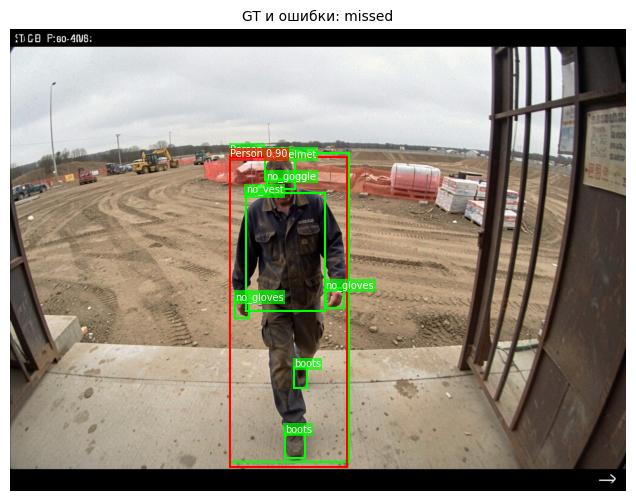

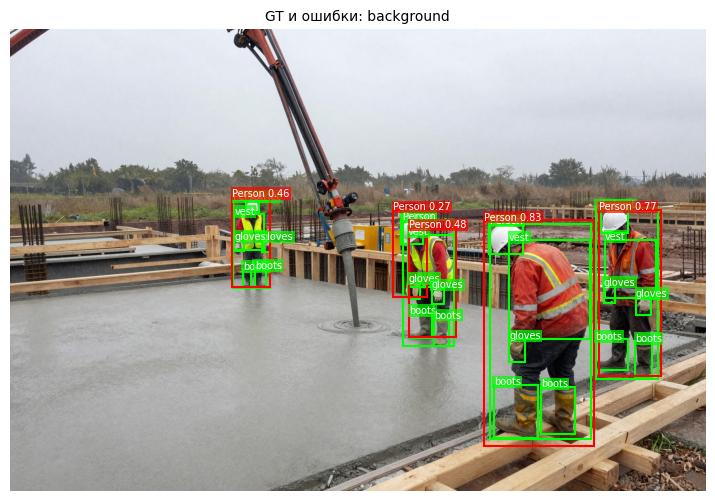

In [40]:
# Разбор ошибок на validation.
error_preds = predict_records(best, records['val'], conf=CONF_ERRORS, batch=BATCH)
ERRORS = Counter()
ERRORS_BY_CLASS = {name: Counter() for name in CLASSES}
error_examples = []
for rec, pred in zip(records['val'], error_preds):
    cats, missed = categorize_predictions(pred, rec)
    for cat, label in zip(cats, pred['labels']):
        ERRORS[cat] += 1
        ERRORS_BY_CLASS[CLASSES[int(label)]][cat] += 1
    ERRORS['missed'] += len(missed)
    for cat in ('class', 'localization', 'background'):
        if cat in cats and len(error_examples) < 12:
            error_examples.append((rec, pred, cats, missed, cat))
    if missed and len(error_examples) < 12:
        error_examples.append((rec, pred, cats, missed, 'missed'))

ERRORS = {key: int(ERRORS[key]) for key in ERROR_TYPES}
print('Ошибки:', ERRORS)
print('По классам:', {k: dict(v) for k, v in ERRORS_BY_CLASS.items()})

shown = set()
for rec, pred, cats, missed, wanted in error_examples:
    if wanted in shown:
        continue
    shown.add(wanted)
    image = np.asarray(Image.open(rec['image']).convert('RGB'))
    fig, ax = plt.subplots(figsize=(9, 6))
    draw_boxes(ax, image, rec['boxes'], rec['labels'], CLASSES, color='lime', title=f'GT и ошибки: {wanted}')
    draw_boxes(ax, None, pred['boxes'], pred['labels'], CLASSES, scores=pred['scores'], color='red')
    plt.show()
    if len(shown) >= 5:
        break

**Ответ:** Основную категорию ошибок можно определить по словарю `ERRORS`: наибольшее число показывает, где модель ошибается чаще всего. При этом отдельные примеры стоит проверить визуально, потому что часть ошибок может быть связана с неполной или неточной разметкой. Если преобладают пропуски, стоит увеличить разрешение, добавить примеры редких классов и подобрать аугментации. Если много ложных срабатываний, полезно проверить сложные фоновые участки и подобрать порог confidence. Если много ошибок локализации, стоит отдельно посмотреть на качество и точность исходных рамок.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [41]:
# Абляция: сравниваем базовый imgsz с уменьшенным 320 при тех же остальных настройках.
ABLATION_ARGS = dict(TRAIN_ARGS)
ABLATION_ARGS['imgsz'] = 320 if IMGSZ != 320 else 640
ab_model, ab_time, ab_dir = train_yolo('ablation_imgsz', **ABLATION_ARGS)
ab_best = YOLO(ab_dir / 'weights' / 'best.pt')
ab_val = val_metrics(ab_best, 'val', 'ablation_val')
ABLATION = {
    'parameter': 'imgsz',
    'baseline_value': IMGSZ,
    'ablation_value': ABLATION_ARGS['imgsz'],
    'baseline_map50': float(VAL_RESULTS['val'].box.map50),
    'baseline_map50_95': float(VAL_RESULTS['val'].box.map),
    'ablation_map50': float(ab_val.box.map50),
    'ablation_map50_95': float(ab_val.box.map),
    'baseline_train_time_sec': float(RUN_TIMES['train']),
    'ablation_train_time_sec': float(ab_time),
}
ABLATION

Ultralytics 8.4.216 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_imgsz, nbs=64, nms=None, opset=None, optimize=False, optimiz

{'parameter': 'imgsz',
 'baseline_value': 320,
 'ablation_value': 640,
 'baseline_map50': 0.06733098621560925,
 'baseline_map50_95': 0.048699925823666605,
 'ablation_map50': 0.06860075209054574,
 'ablation_map50_95': 0.045810449619198765,
 'baseline_train_time_sec': 92.37377676400001,
 'ablation_train_time_sec': 260.7164292739999}

**Ответ:** В абляции меняется только размер входного изображения, остальные параметры обучения остаются такими же. При меньшем `imgsz` обучение и инференс обычно быстрее, но мелкие объекты могут терять детали. Решение о том, оправдано ли уменьшение разрешения, нужно принимать по разнице mAP50 и mAP50-95 вместе со временем обучения из `ABLATION`. Если качество почти не изменилось, меньший размер может быть практичнее; если метрики заметно упали, экономия времени не компенсирует потерю точности.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** В работе была дообучена компактная модель YOLO26n на датасете Construction-PPE с 12 классами. Качество исходной COCO-модели и простого бейзлайна сравнивалось с результатом после дообучения на одном и том же validation-сплите. Основные итоговые значения mAP50, mAP50-95, precision и recall находятся в `FINAL`, а время обучения — в `RUN_TIMES`. По распределению ошибок можно определить, какие классы модель распознаёт хуже и что чаще встречается: пропуски, неверная локализация или ложные срабатывания. В абляции проверено влияние размера изображения на качество и время обучения. Результаты следует считать предварительными, поскольку используется один seed, а размер validation меньше обучающей выборки. В дальнейшем я бы увеличил количество примеров редких классов и проверил модель на независимых изображениях из реальных условий.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [42]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [ ]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус 6.1 не выполнялся: дополнительные 50 изображений не размечались.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [ ]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус 6.2 не выполнялся: сравнение с RT-DETR не проводилось.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [ ]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус 6.3 не выполнялся: устойчивость к искусственным искажениям отдельно не измерялась.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [ ]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус 6.4 не выполнялся: экспорт в ONNX и замер скорости не проводились.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [ ]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус 6.5 не выполнялся: сетка порогов confidence и IoU не исследовалась.